#Exploratory Data Analysis Report

##Step 1: Verifying Samples and Clinical Data
Since the clinical data (like ER status, relapse status, lymph node status) is being pulled from the GEO Omnibus, it must be converted into a format that is machine readable. When downloading from the source, it downloads as a txt. This section below formats the txt into a dataframe. It also renames some of the key column headers, so that they will match the other data files.
### Results Review
The expression matrix, ABS detection, P-value detection and clinical parameters dataset do not have any missing information. <br>
The annotation dataset has some missing values. the most important to note for this project are:


*   Gene Title
*   Gene Symbol



In [49]:
'''Converting Clinical Data txt file into dataframe'''
import pandas as pd
import matplotlib.pyplot as plt
clinical_data = pd.read_csv('clinical_data.txt', sep="\t")
#print (clinical_data)
clinical_parameters_df = pd.DataFrame(clinical_data)
'''renaming the column names to avoid any special character issues down the line'''
clinical_parameters_df.rename(columns={"GEO asscession number":"Sample_Accession", "relapse (1=True)":"Relapse", "ER Status":"ER_status"},inplace=True)
print (clinical_parameters_df)
print ('\nCount of NaN in each column:\n', clinical_parameters_df.isnull().sum())

     PID Sample_Accession lymph node status  \
0      3         GSM36793          negative   
1      5         GSM36796          negative   
2      6         GSM36797          negative   
3      7         GSM36798          negative   
4      8         GSM36800          negative   
..   ...              ...               ...   
281  900         GSM36887          negative   
282  901         GSM36889          negative   
283  903         GSM36892          negative   
284  909         GSM36894          negative   
285  913         GSM36911          negative   

     time to relapse or last follow-up (months)  Relapse ER_status  \
0                                           101        0       ER-   
1                                           118        0       ER+   
2                                             9        1       ER-   
3                                           106        0       ER-   
4                                            37        1       ER-   
..             

In [50]:
'''Convert Expression Matrix into Dataframe'''

gene_seq_data = pd.read_csv('GSE2034_family_expression_matrix.csv', sep=",")
gene_seq_df = pd.DataFrame(gene_seq_data)
print (gene_seq_df)

print ('\nCount of NaN in each column:\n', gene_seq_df.isnull().sum())

               ID_REF  GSM36777  GSM36778  GSM36779  GSM36780  GSM36781  \
0      AFFX-BioB-5_at     467.7     754.0     981.4     899.2     730.1   
1      AFFX-BioB-M_at     919.8    1663.8    2094.1    1733.8    1592.3   
2      AFFX-BioB-3_at     468.3     996.3    1029.3     906.8     637.0   
3      AFFX-BioC-5_at    1371.1    2511.1    2699.7    2756.9    2158.4   
4      AFFX-BioC-3_at    1048.2    1930.7    1941.4    1658.2    1675.9   
...               ...       ...       ...       ...       ...       ...   
22278     222380_s_at     423.1    1911.9     186.3     378.6     726.5   
22279       222381_at      36.9     134.5      90.4     153.1      98.4   
22280     222382_x_at     120.2      27.9      69.9     170.3     189.4   
22281     222383_s_at      18.7      42.7      10.5       5.5      23.2   
22282       222384_at      89.4      33.9      57.7      21.8      23.2   

       GSM36782  GSM36783  GSM36784  GSM36785  ...  GSM37053  GSM37054  \
0         838.5     756.9

In [51]:
'''Convert ABS DETECTION data file into dataframe'''

PAM_data= pd.read_csv('GSE2034_family_matrix_ABS_CALL.csv', sep=",")
PAM_data_df = pd.DataFrame(PAM_data)
print (PAM_data_df)

print ('\nCount of NaN in each column:\n', PAM_data_df.isnull().sum())

               ID_REF GSM36777 GSM36778 GSM36779 GSM36780 GSM36781 GSM36782  \
0      AFFX-BioB-5_at        P        P        P        P        P        P   
1      AFFX-BioB-M_at        P        P        P        P        P        P   
2      AFFX-BioB-3_at        P        P        P        P        P        P   
3      AFFX-BioC-5_at        P        P        P        P        P        P   
4      AFFX-BioC-3_at        P        P        P        P        P        P   
...               ...      ...      ...      ...      ...      ...      ...   
22278     222380_s_at        P        P        P        P        P        P   
22279       222381_at        A        A        A        A        A        A   
22280     222382_x_at        A        A        A        P        A        A   
22281     222383_s_at        A        A        A        A        A        A   
22282       222384_at        A        A        A        A        A        A   

      GSM36783 GSM36784 GSM36785  ... GSM37053 GSM3

In [52]:
'''Convert Detection P-value file into dataframe'''
P_data= pd.read_csv('GSE2034_family_matrix_DETECTION_P_VALUE.csv', sep=",")
P_data_df = pd.DataFrame(P_data)
print (P_data_df)

print ('\nCount of NaN in each column:\n', P_data_df.isnull().sum())

               ID_REF  GSM36777  GSM36778  GSM36779  GSM36780  GSM36781  \
0      AFFX-BioB-5_at  0.002023  0.001248  0.000390  0.000972  0.001593   
1      AFFX-BioB-M_at  0.000081  0.000044  0.000044  0.000052  0.000095   
2      AFFX-BioB-3_at  0.000195  0.000052  0.000052  0.000060  0.000127   
3      AFFX-BioC-5_at  0.000127  0.000110  0.000081  0.000110  0.000195   
4      AFFX-BioC-3_at  0.000070  0.000081  0.000070  0.000070  0.000060   
...               ...       ...       ...       ...       ...       ...   
22278     222380_s_at  0.000732  0.000244  0.030273  0.000732  0.000732   
22279       222381_at  0.334473  0.219482  0.111572  0.111572  0.303711   
22280     222382_x_at  0.129639  0.303711  0.171387  0.030273  0.095215   
22281     222383_s_at  0.500000  0.533936  0.919434  0.780518  0.665527   
22282       222384_at  0.067627  0.432373  0.246094  0.432373  0.423828   

       GSM36782  GSM36783  GSM36784  GSM36785  ...  GSM37053  GSM37054  \
0      0.000446  0.000509

In [53]:
'''inspect master file for any missing values'''
import numpy as np

missing_values_master = gene_seq_df.isnull().any(axis=1).sum()
missing_values_PAM = PAM_data_df.isnull().any(axis=1).sum()
missing_values_P = P_data_df.isnull().any(axis=1).sum()

print ("Number of missing data in Master File:", missing_values_master)
print ("Number of missing data in PAM File:", missing_values_PAM)
print ("Number of missing data in P-value File:", missing_values_P)

Number of missing data in Master File: 0
Number of missing data in PAM File: 0
Number of missing data in P-value File: 0


In [54]:
'''Investigating shapes of 3 dataframes'''

print ("Shape of gene_seq_df:", gene_seq_df.shape)
print ("Shape of PAM_data_df:", PAM_data_df.shape)
print ("Shape of P_data_df:", P_data_df.shape)

Shape of gene_seq_df: (22283, 287)
Shape of PAM_data_df: (22283, 287)
Shape of P_data_df: (22283, 287)


In [55]:
'''Putting Headers in a list to compare'''

master_headers = list(gene_seq_df.columns.values)
PAM_headers = list(PAM_data_df.columns.values)
P_headers = list(P_data_df.columns.values)


'''Testing to see if the lists are identical'''

master_vs_PAM = master_headers == PAM_headers
master_vs_P = master_headers == P_headers

print ("Is Master Header Identical to PAM header:", master_vs_PAM)
print ("Is Master Header Identical to P header:", master_vs_P)


'''Putting values of first column (Probe ID's) in a list to compare'''

master_ProbeID = gene_seq_df['ID_REF'].values.tolist()
PAM_ProbeID = PAM_data_df['ID_REF'].values.tolist()
P_ProbeID = P_data_df['ID_REF'].values.tolist()

'''Comparing Master first column to PAM and Pvalue'''

master_probe_pam = master_ProbeID == PAM_ProbeID
master_probe_p = master_ProbeID == P_ProbeID

print ("Is Master ProbeID Identical to PAM ProbID:", master_probe_pam)
print ("Is Master ProbID Identical to P ProbID:", master_probe_p)

Is Master Header Identical to PAM header: True
Is Master Header Identical to P header: True
Is Master ProbeID Identical to PAM ProbID: True
Is Master ProbID Identical to P ProbID: True


In [56]:
'''Convert Gene Annotation File into dataframe'''

annotation_data = pd.read_csv('GSE2034_family_platform_GPL96_annotation.csv', sep=",")
annotation_data_df = pd.DataFrame(annotation_data)
print (annotation_data_df)

print ('\nCount of NaN in each column:\n', annotation_data_df.isnull().sum())

                    ID  GB_ACC    SPOT_ID Species Scientific Name  \
0            1007_s_at  U48705        NaN            Homo sapiens   
1              1053_at  M87338        NaN            Homo sapiens   
2               117_at  X51757        NaN            Homo sapiens   
3               121_at  X69699        NaN            Homo sapiens   
4            1255_g_at  L36861        NaN            Homo sapiens   
...                ...     ...        ...                     ...   
22278   AFFX-ThrX-5_at     NaN  --Control            Homo sapiens   
22279   AFFX-ThrX-M_at     NaN  --Control            Homo sapiens   
22280  AFFX-TrpnX-3_at     NaN  --Control            Homo sapiens   
22281  AFFX-TrpnX-5_at     NaN  --Control            Homo sapiens   
22282  AFFX-TrpnX-M_at     NaN  --Control            Homo sapiens   

      Annotation Date      Sequence Type                  Sequence Source  \
0         Oct 6, 2014  Exemplar sequence  Affymetrix Proprietary Database   
1         Oct 6, 

## Step 2: Exploratory Quality Checks
Plotting distribution across samples of:


*   Relapse vs Relapse Free status
*   ER + vs ER - Status
*   Expression Matrix Distribution
*   Present / Absent / Marginal Distribution
*   P-value of signal detection (signal vs noise detection) distribution
###Results Review






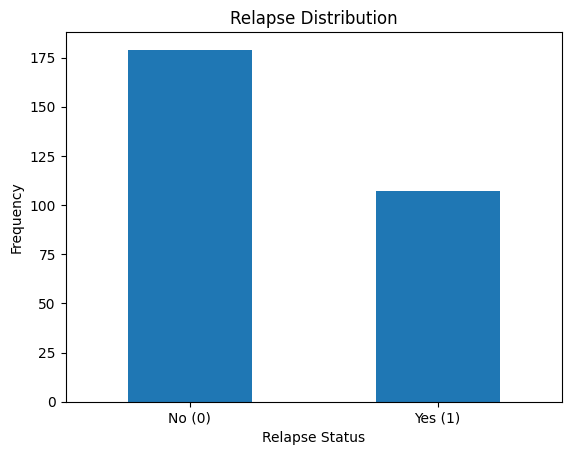

Relapse Count Relapse
0    179
1    107
Name: count, dtype: int64
Relapse Percentage Relapse
0    62.587413
1    37.412587
Name: count, dtype: float64


In [57]:
'''Distribution of how many patients relapsed versus relapse free'''
relapse_counts = clinical_parameters_df['Relapse'].value_counts()

'''Plotting and customizing the look of the plot'''
relapse_counts.plot(kind='bar', rot=0)
plt.title('Relapse Distribution')
plt.xlabel('Relapse Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()
#print (relapse_counts)

'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
relapse_percentage = ((relapse_counts / len(clinical_parameters_df)) * 100)
print("Relapse Count", relapse_counts)
print("Relapse Percentage", relapse_percentage)


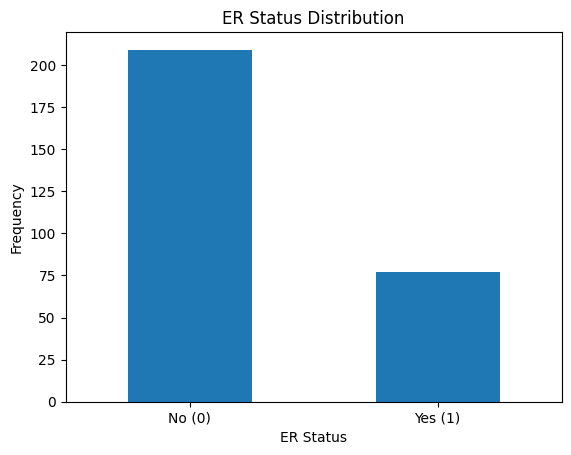

Relapse Count ER_status
ER+    209
ER-     77
Name: count, dtype: int64
Relapse Percentage ER_status
ER+    73.076923
ER-    26.923077
Name: count, dtype: float64


In [58]:
'''Distribution of ER Status'''
ER_counts = clinical_parameters_df['ER_status'].value_counts()

'''Plotting and customizing the look of the plot'''
ER_counts.plot(kind='bar', rot=0)
plt.title('ER Status Distribution')
plt.xlabel('ER Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()


'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
ER_percentage = ((ER_counts / len(clinical_parameters_df)) * 100)
print("Relapse Count", ER_counts)
print("Relapse Percentage", ER_percentage)

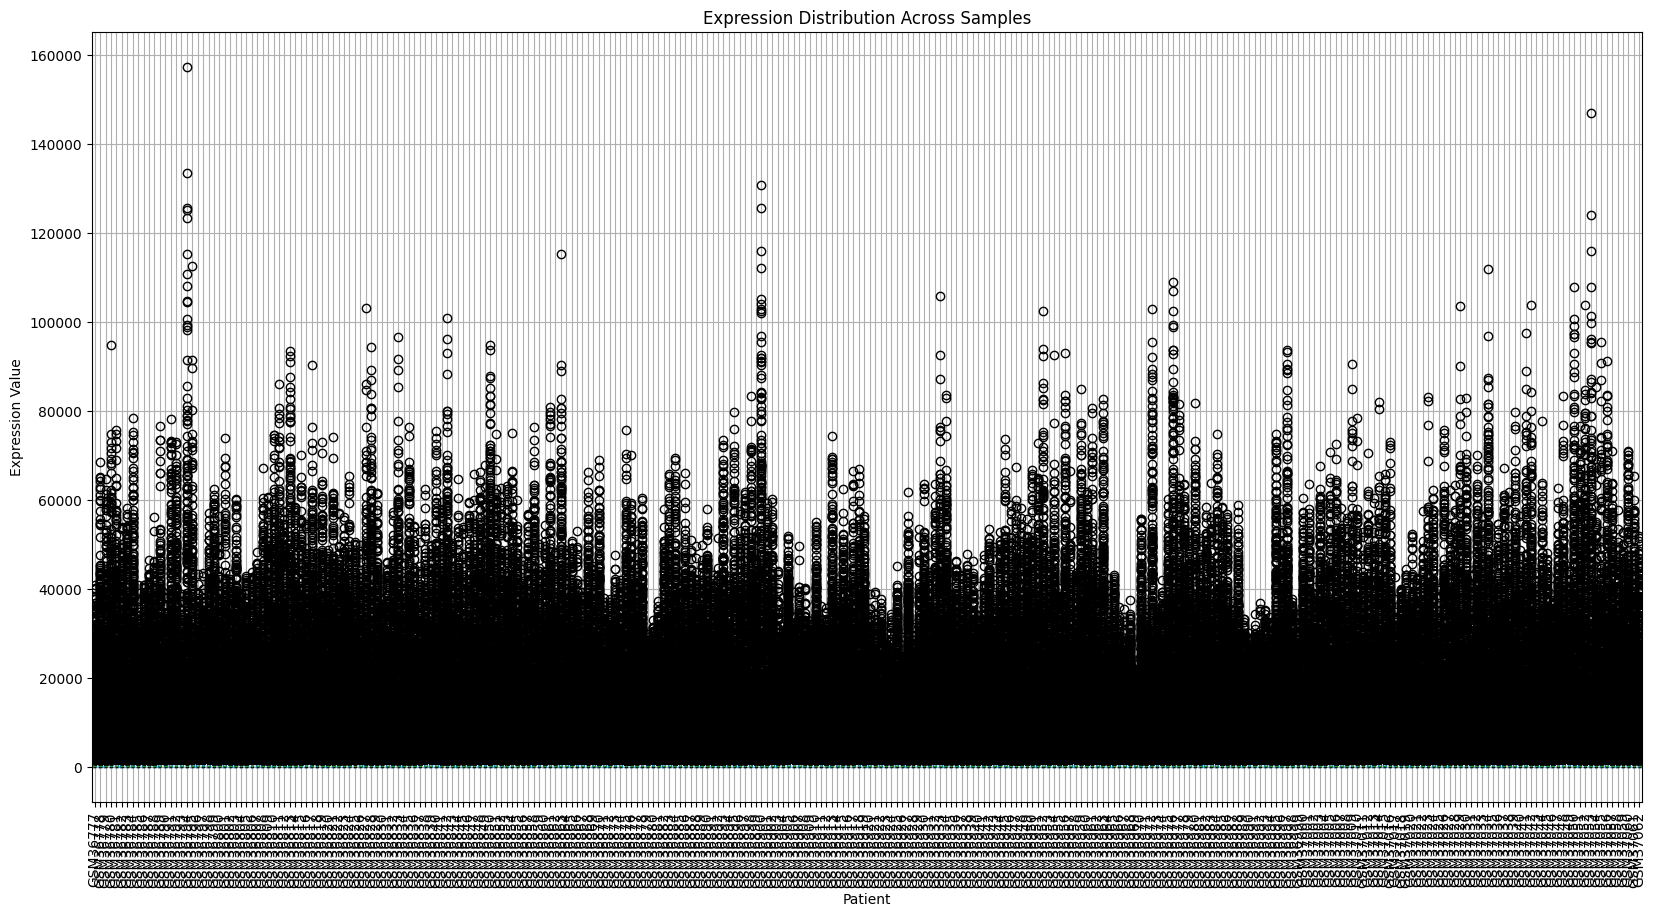

In [59]:
'''Expression Matrix Distribution- Box Plot'''
import matplotlib.pyplot as plt

gene_seq_df.boxplot(figsize=(20,10))
plt.xticks(rotation=90)
plt.ylabel("Expression Value")
plt.xlabel("Patient")
plt.title("Expression Distribution Across Samples")

plt.show()

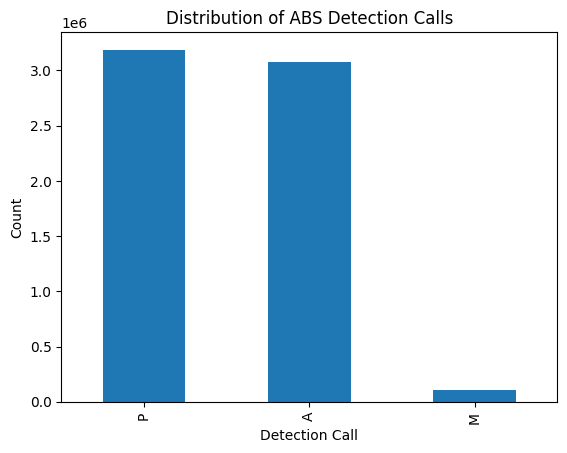


 Number of values by Type:
 P    3187954
A    3076782
M     108202
Name: count, dtype: int64

 Percentage of detections marked Present:

P: 50.02 %
A: 48.28 %
M: 1.7 %


In [60]:
'''ABS Detection Distribution'''
#Distribution of how many values are marked Present vs Absent vs Marginal
PAM_values = PAM_data_df.iloc[:,1:]

call_counts=PAM_values.stack().value_counts()

call_counts.plot(kind='bar')
plt.xticks(rotation=90)
plt.ylabel("Count")
plt.xlabel("Detection Call")
plt.title("Distribution of ABS Detection Calls")

plt.show()

'''Distributions by Number'''
p_percent = round((call_counts.get('P',0)/ PAM_values.size)*100, 2)
a_percent = round((call_counts.get('A',0)/ PAM_values.size)*100, 2)
m_percent = round((call_counts.get('M',0)/ PAM_values.size)*100, 2)

print ('\n Number of values by Type:\n', call_counts)
print ('\n Percentage of detections marked Present:\n')
print ('P:', p_percent, '%')
print ('A:', a_percent, '%')
print ('M:', m_percent, '%')


In [61]:
''' How many ProbeID rows are CONSISTENTLY marked Present'''
pam_value_row = PAM_data_df.iloc[:,1:]

#how many samples in each row are marked present. The output will be a value
#between 0 to 1. 0 = no values in the row marked present
# 1 = all values in the row not marked present

present_detection_rate = (pam_value_row == 'P').mean(axis = 1)

#summarizing

present_detection_summary = pd.DataFrame ( {
    'ID_REF': PAM_data_df.iloc[:,0],
    'Detection_Rate' : present_detection_rate.values
})


print (present_detection_summary)

#print (p_value_row.shape, p_value_row.dtypes.value_counts())

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22278     222380_s_at        0.996503
22279       222381_at        0.062937
22280     222382_x_at        0.300699
22281     222383_s_at        0.003497
22282       222384_at        0.000000

[22283 rows x 2 columns]


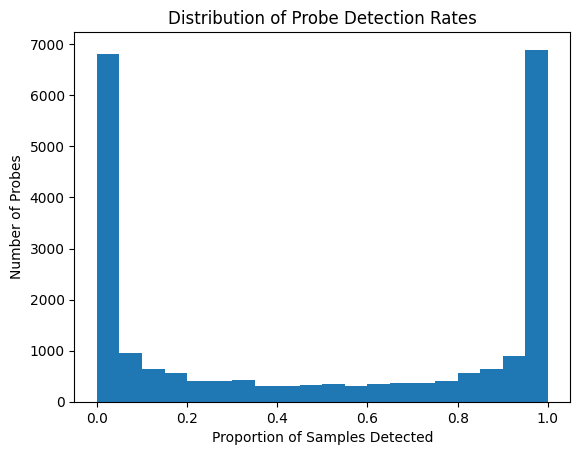

In [62]:
'''Visualizing detection rates in histogram'''

plt.hist(present_detection_summary['Detection_Rate'], bins =20)

plt.ylabel("Number of Probes")
plt.xlabel("Proportion of Samples Detected")
plt.title("Distribution of Probe Detection Rates")

plt.show()


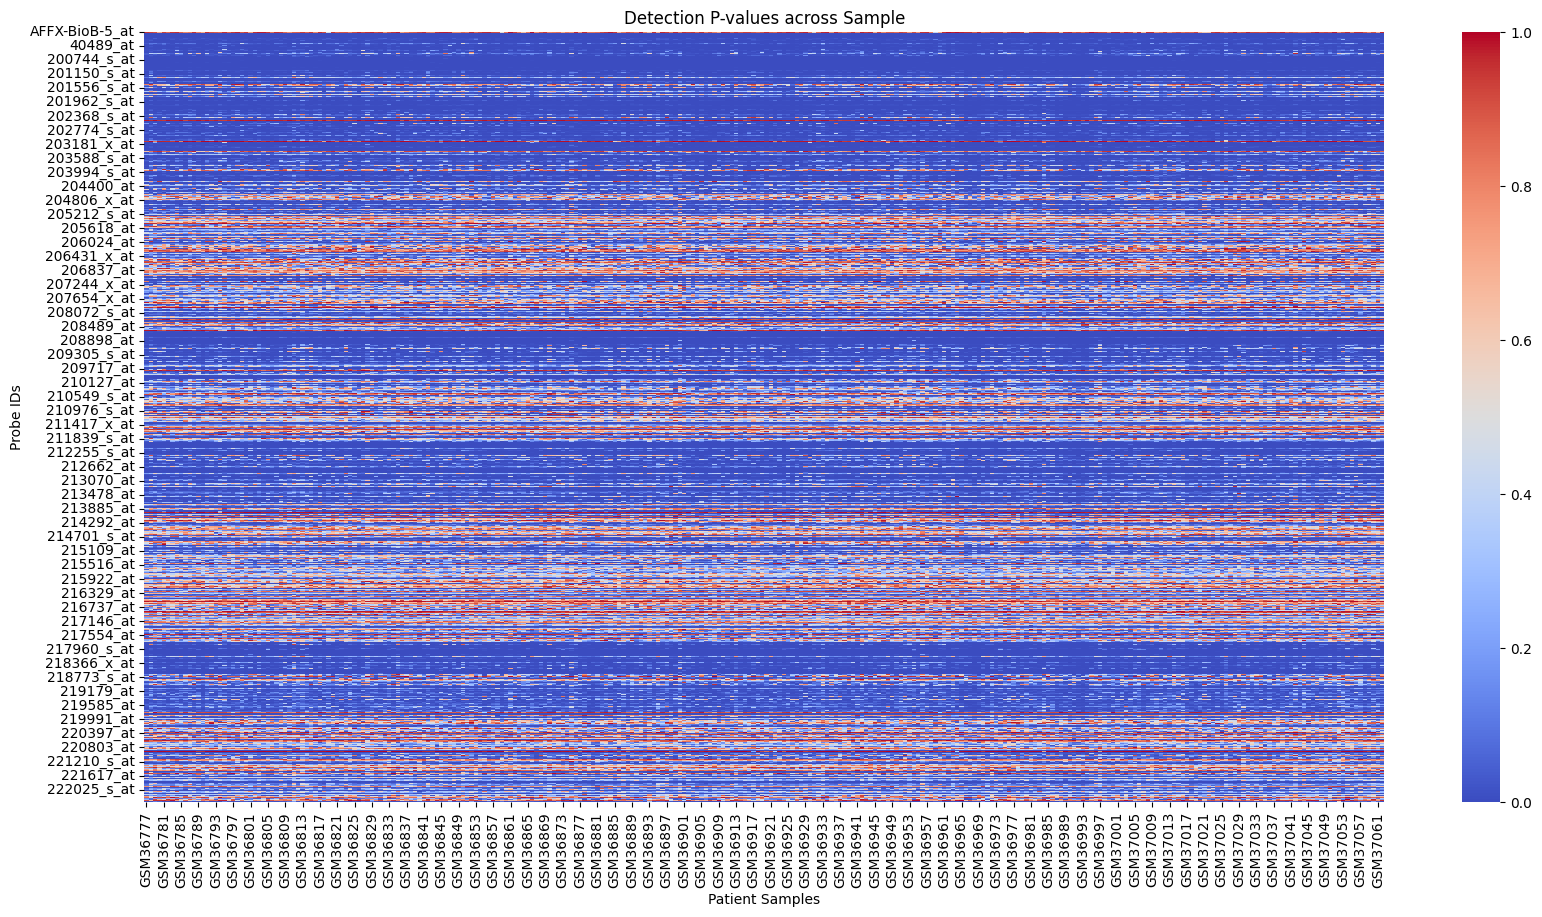

In [63]:
'''P-value Distribution'''
#Using a heat map will allow for easy spotting of probe IDs that are
#reliably meeting the p-value threshold, and ones that are not meeting
#the p-value threshold.

import seaborn as sns

P_values = P_data_df.set_index('ID_REF')

#sample_probes = P_values.sample(n=100, random_state=42)
plt.figure(figsize=(20,10))

sns.heatmap(
    P_values,
    cmap='coolwarm',
    vmin=0,
    vmax=1
)

plt.ylabel("Probe IDs")
plt.xlabel("Patient Samples")
plt.title("Detection P-values across Sample")

plt.show()

In [64]:
''' How many Probes are CONSISTENTLY 'reliable' at detecting signal'''
p_value_row = P_data_df.iloc[:,1:]

#how many samples in each row met the threshold. The output will be a value
#between 0 to 1. 0 = no values in the row meet the threshold
# 1 = all values in the row meet the threshold

detection_rate = (p_value_row < 0.05).mean(axis = 1)

#summarizing

detection_summary = pd.DataFrame ( {
    'ID_REF': P_data_df.iloc[:,0],
    'Detection_Rate' : detection_rate.values
})

print (detection_summary)

print (p_value_row.shape, p_value_row.dtypes.value_counts())

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22278     222380_s_at        0.996503
22279       222381_at        0.062937
22280     222382_x_at        0.300699
22281     222383_s_at        0.003497
22282       222384_at        0.000000

[22283 rows x 2 columns]
(22283, 286) float64    286
Name: count, dtype: int64


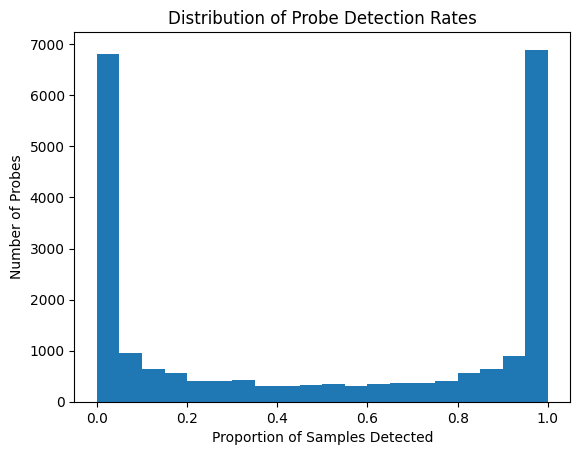

In [65]:
'''Visualizing detection rates in histogram'''

plt.hist(detection_summary['Detection_Rate'], bins =20)

plt.ylabel("Number of Probes")
plt.xlabel("Proportion of Samples Detected")
plt.title("Distribution of Probe Detection Rates")

plt.show()

## Step 3. Filtering Unreliable ProbeIDs
We have a distribution of how proportionally reliable each ProbeID is. The next step is filtering out the probeIDs that produce very weak/unrealible signals. There are various methodologies for filtering the low signal ProbeIDs. One paper cited success in filtering out ProbeIDs that have less than 50% 'Present' marked values in the row. I will employ this method for the ABS data, and also for the p-value data. And compare the results.

##Results

Both filtering methods had the same result.

In [66]:
'''Filter out ProbeIDs that have a detection rate of less than 0.5 from PAM'''

filtered_present_detection_df = present_detection_summary.loc[present_detection_summary['Detection_Rate'] >= 0.5, ['ID_REF', 'Detection_Rate']]

print (filtered_present_detection_df)

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22268     222370_x_at        0.905594
22269       222371_at        0.849650
22274       222376_at        0.856643
22277       222379_at        0.667832
22278     222380_s_at        0.996503

[11130 rows x 2 columns]


In [68]:
'''Filter out ProbeIDs that have a detection rate of less than 0.5 from P-value'''

filtered_p_detection_df = detection_summary.loc[detection_summary['Detection_Rate'] >= 0.5, ['ID_REF', 'Detection_Rate']]

print (filtered_p_detection_df)

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22268     222370_x_at        0.905594
22269       222371_at        0.849650
22274       222376_at        0.856643
22277       222379_at        0.667832
22278     222380_s_at        0.996503

[11130 rows x 2 columns]


In [70]:
'''Comparing resulting dataframes'''

print (filtered_present_detection_df.equals(filtered_p_detection_df))

True


In [72]:
'''Getting a list of the ProbeIDs that are significant enough to keep'''

probes_to_keep = filtered_present_detection_df['ID_REF']

In [73]:
filtered_expression_df = gene_seq_df[gene_seq_df['ID_REF'].isin(probes_to_keep)]

print (filtered_expression_df)

               ID_REF  GSM36777  GSM36778  GSM36779  GSM36780  GSM36781  \
0      AFFX-BioB-5_at     467.7     754.0     981.4     899.2     730.1   
1      AFFX-BioB-M_at     919.8    1663.8    2094.1    1733.8    1592.3   
2      AFFX-BioB-3_at     468.3     996.3    1029.3     906.8     637.0   
3      AFFX-BioC-5_at    1371.1    2511.1    2699.7    2756.9    2158.4   
4      AFFX-BioC-3_at    1048.2    1930.7    1941.4    1658.2    1675.9   
...               ...       ...       ...       ...       ...       ...   
22268     222370_x_at     151.0     246.2     148.3     191.8     308.5   
22269       222371_at     198.4     348.7      83.2     144.7     318.8   
22274       222376_at     211.4     300.2     269.7     255.1     294.0   
22277       222379_at     883.4     857.8    5459.4     122.2      86.4   
22278     222380_s_at     423.1    1911.9     186.3     378.6     726.5   

       GSM36782  GSM36783  GSM36784  GSM36785  ...  GSM37053  GSM37054  \
0         838.5     756.9